In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

In [6]:
# Create Sample Dataset
salary = np.array([
    25000, 28000, 30000, 32000, 35000,
    27000, 31000, 33000, 36000, 29000,
    34000, 37000, 40000, 31000, 35000,
    38000, 42000, 30000, 33000, 36000
])

In [14]:
confidence_interval = stats.norm.interval(
    confidence=0.95,
    loc=np.mean(salary),
    scale=stats.sem(salary)
)

print("95% Confidence Interval:", confidence_interval)

95% Confidence Interval: (np.float64(31177.005052001936), np.float64(35022.994947998064))


In [15]:
# OR
stats.norm.interval(
    confidence=0.95,
    loc=np.mean(salary),
    scale=population_std / np.sqrt(len(salary))
)

print("95% Confidence Interval:", confidence_interval)

NameError: name 'population_std' is not defined

In [13]:
# Alternative: Calculate using Z critical value
sample_mean = np.mean(salary)
sample_std = np.std(salary, ddof=1)
n = len(salary)

standard_error = sample_std / np.sqrt(n)

z_critical = stats.norm.ppf(0.975)

margin_error = z_critical * standard_error

lower = sample_mean - margin_error
upper = sample_mean + margin_error

print("Lower Limit:", lower)
print("Upper Limit:", upper)

Lower Limit: 31177.005052001936
Upper Limit: 35022.994947998064


In [7]:
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(salary)-1,
    loc=np.mean(salary),
    scale=stats.sem(salary)
)

print("95% Confidence Interval:", confidence_interval)

95% Confidence Interval: (np.float64(31046.45477446866), np.float64(35153.545225531336))


In [8]:
# Calculate Different Confidence Intervals
confidence_levels = [0.90, 0.95, 0.99]

for confidence in confidence_levels:

    ci = stats.t.interval(
        confidence=confidence,
        df=len(salary)-1,
        loc=np.mean(salary),
        scale=stats.sem(salary)
    )

    print(f"{confidence*100}% Confidence Interval:", ci)

90.0% Confidence Interval: (np.float64(31403.482264367427), np.float64(34796.51773563257))
95.0% Confidence Interval: (np.float64(31046.45477446866), np.float64(35153.545225531336))
99.0% Confidence Interval: (np.float64(30293.02862798469), np.float64(35906.97137201531))


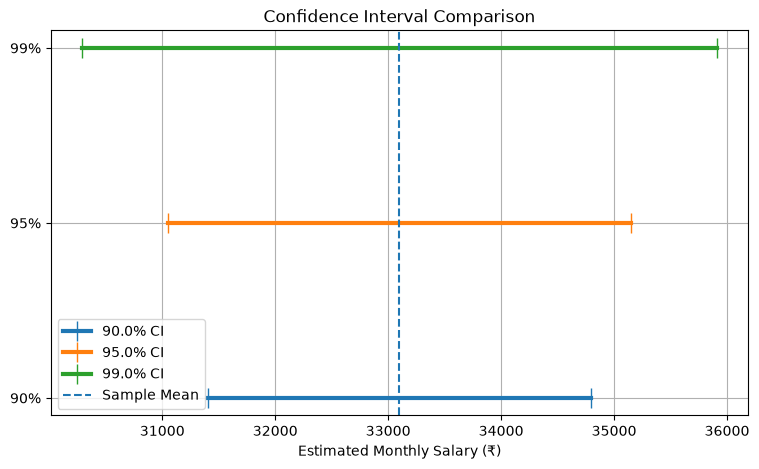

In [9]:
confidence_levels = [0.90, 0.95, 0.99]

sample_mean = np.mean(salary)

plt.figure(figsize=(9, 5))

for i, confidence in enumerate(confidence_levels):

    ci = stats.t.interval(
        confidence=confidence,
        df=len(salary)-1,
        loc=sample_mean,
        scale=stats.sem(salary)
    )

    lower, upper = ci

    plt.plot(
        [lower, upper],
        [i, i],
        marker='|',
        markersize=15,
        linewidth=3,
        label=f"{confidence*100}% CI"
    )

plt.axvline(
    sample_mean,
    linestyle='--',
    label='Sample Mean'
)

plt.yticks([0, 1, 2], ['90%', '95%', '99%'])

plt.xlabel("Estimated Monthly Salary (₹)")
plt.title("Confidence Interval Comparison")

plt.legend()
plt.grid()
plt.show()